# RMTB/RMTC vs. other tensor-product splines, 2-D (Part I: mean-fit comparison)

Implements Part I of `docs/RMTS variance implementation plan.md`. Purpose (see that
doc): find out **where RMTS's mean fit itself is weak** relative to other
tensor-product spline implementations, before building variance on top of it
(Phase D, "Gaussian RMTS", in `docs/Research Plan - From Fundamentals to Gaussian
RMTS.md`). This is a different question from the isotropic-Kriging-target
comparisons in `02_2d_splines_vs_kriging.ipynb` -- here RMTB/RMTC are compared
against *other additive/tensor-product methods*, to separate "is the known
`~6-10%` floor structural to the additive-energy model class (Proposition 10)" from
"is it an RMTB/RMTC-specific weakness."

**Failure criterion** (stated up front, not decided after seeing results): RMTB or
RMTC is flagged as underperforming a case if its best-tuned RMSE exceeds every
applicable alternative's best-tuned RMSE by more than 2x, or if it is numerically
suspect (`cond(mtx) > 1e8`) regardless of RMSE.


## Method applicability (fixed per dataset type)

`RectBivariateSpline` and `csaps.NdGridCubicSmoothingSpline` are structurally
grid-only (already established in `02_2d_splines_vs_kriging.ipynb`). Only
`SmoothBivariateSpline` accepts scattered data. So:

- **Grid datasets:** RMTB/RMTC vs. all three alternatives.
- **Scattered datasets:** RMTB/RMTC vs. `SmoothBivariateSpline` only.


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import SmoothBivariateSpline, RectBivariateSpline
from scipy.optimize import minimize_scalar
from csaps import NdGridCubicSmoothingSpline
from smt.surrogate_models import RMTB, RMTC

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})

XLIMITS = np.array([[0., 1.], [0., 1.]])


def true_f(X):
    return np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1])


def dense_eval_grid(n=61):
    g = np.linspace(0, 1, n)
    GX, GY = np.meshgrid(g, g, indexing="ij")
    return np.column_stack([GX.ravel(), GY.ravel()])


Xq_dense = dense_eval_grid()
yq_true = true_f(Xq_dense)


def rmse_vs_truth(pred):
    return float(np.sqrt(np.mean((np.ravel(pred) - yq_true) ** 2)))


def max_err_vs_truth(pred):
    return float(np.max(np.abs(np.ravel(pred) - yq_true)))


## Compute-budget caps (stated up front)

RMTB's system size is `m = num_ctrl_pts**2`; RMTC's is `dof = 4*(num_elements+1)**2`
(Hermite elements carry 4 dof/node -- confirmed directly: `num_elements=30` gives
`mtx.shape=(3844,3844)`, matching `4*31**2` exactly, and `num_elements=25` gives
`(2704,2704)`, matching `4*26**2`). `cond(mtx)` (full dense SVD) is the dominant
cost, not training: checked directly at `~7s` per call around `m~3600-3800`
(`~4.7s` confirmed for RMTC at `num_elements=25`), growing to `~37s` by `m~6400`,
with training itself already exceeding a minute by `m~10000`. To keep this
notebook's full sweep (4 datasets x 3 resolution tiers x 2 RMTS models x 4
energy_weight trials, plus a conditioning check on every best-tuned config)
tractable to build and re-execute interactively, resolution is capped at
**`num_ctrl_pts<=60`** for RMTB and **`num_elements<=25`** for RMTC (both land
around `m~2700-3600`, keeping every `cond(mtx)` call in the `~5-7s` range rather
than the `~37s` range).

This means, for the two datasets whose *native* per-dimension point count already
exceeds these caps (the 40x40 fine grid, and the 3000-point dense scattered set,
whose effective `sqrt(n)~55`), the "mid" and/or "high" resolution tiers collapse to
the same capped value instead of showing the literal 3x/10x multiplier -- reported
as a finding about relative cost at scale, not hidden. The two lower-resolution
datasets (8x8 sparse grid, 180-point sparse scattered) keep all three tiers distinct
for RMTB; RMTC's lower cap means even those two collapse its "mid"/"high" tiers
together in some cases -- read off the printed resolution values per case rather
than assuming "low/mid/high" always means three genuinely different sizes.


In [2]:
RMTB_CAP = 60
RMTC_CAP = 25
ENERGY_WEIGHTS = [1e-6, 1e-4, 1e-2, 1.0]
REG_WEIGHT = 1e-14


def resolution_tiers(n_side, rmtb_cap=RMTB_CAP, rmtc_cap=RMTC_CAP):
    raw = {"low": n_side, "mid": 3 * n_side, "high": 10 * n_side}
    rmtb = {k: min(v, rmtb_cap) for k, v in raw.items()}
    rmtc = {k: min(v, rmtc_cap) for k, v in raw.items()}
    return raw, rmtb, rmtc


## Fitting helpers (RMTB/RMTC tuned over `energy_weight`, conditioning diagnostics, alternatives)

In [3]:
def fit_rmtb_tuned(X, y, num_ctrl_pts):
    best = None
    for ew in ENERGY_WEIGHTS:
        m = RMTB(xlimits=XLIMITS, order=4, approx_order=2, num_ctrl_pts=num_ctrl_pts,
                  energy_weight=ew, regularization_weight=REG_WEIGHT, solver="dense-lu",
                  print_global=False)
        m.set_training_values(X, y)
        m.train()
        rmse = rmse_vs_truth(m.predict_values(Xq_dense))
        if best is None or rmse < best[1]:
            best = (m, rmse, ew)
    return best  # (model, rmse, best_energy_weight)


def fit_rmtc_tuned(X, y, num_elements):
    best = None
    for ew in ENERGY_WEIGHTS:
        m = RMTC(xlimits=XLIMITS, num_elements=num_elements, approx_order=2,
                  energy_weight=ew, regularization_weight=REG_WEIGHT, solver="dense-lu",
                  print_global=False)
        m.set_training_values(X, y)
        m.train()
        rmse = rmse_vs_truth(m.predict_values(Xq_dense))
        if best is None or rmse < best[1]:
            best = (m, rmse, ew)
    return best


def rmts_diagnostics(model, y):
    # cond(mtx) and the plain-solve-vs-SVD-solve gap, per
    # RMTS_variance_potential_issues.md's methodology.
    mtx = model.mtx.toarray()
    cond = np.linalg.cond(mtx)
    PhiT = model.full_jac_dict[0][1]
    rhs = np.asarray(PhiT @ y.reshape(-1, 1)).ravel()
    w_solve = np.linalg.solve(mtx, rhs)
    w_lstsq, *_ = np.linalg.lstsq(mtx, rhs, rcond=None)
    denom = max(np.max(np.abs(w_lstsq)), 1e-300)
    rel_gap = float(np.max(np.abs(w_solve - w_lstsq)) / denom)
    sol_gap = float(np.max(np.abs(w_solve - model.sol.ravel())))
    suspect = cond > 1e8
    return dict(cond=float(cond), solve_lstsq_rel_gap=rel_gap,
                sol_vs_textbook_gap=sol_gap, suspect=suspect)


In [4]:
def fit_smooth_bivariate_tuned(X, y):
    def err(log_s):
        s = 10 ** log_s
        try:
            sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s)
            return rmse_vs_truth(sp.ev(Xq_dense[:, 0], Xq_dense[:, 1]))
        except Exception:
            return 1e3
    res = minimize_scalar(err, bounds=(-6, 3), method="bounded", options={"xatol": 1e-2})
    s_best = 10 ** res.x
    sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s_best)
    rmse = rmse_vs_truth(sp.ev(Xq_dense[:, 0], Xq_dense[:, 1]))
    return dict(name="SmoothBivariateSpline", rmse=rmse, param=s_best)


def fit_rect_bivariate(g_side, Z):
    rbs = RectBivariateSpline(g_side, g_side, Z, kx=3, ky=3, s=0)
    rmse = rmse_vs_truth(rbs.ev(Xq_dense[:, 0], Xq_dense[:, 1]))
    return dict(name="RectBivariateSpline", rmse=rmse, param=0.0)


def fit_csaps_tuned(g_side, Z):
    def err(s):
        sp = NdGridCubicSmoothingSpline([g_side, g_side], Z, smooth=[s, s])
        gq = np.linspace(0, 1, 61)
        pred = sp([gq, gq]).ravel()
        return rmse_vs_truth(pred)
    res = minimize_scalar(err, bounds=(1e-6, 1 - 1e-9), method="bounded", options={"xatol": 1e-6})
    rmse = err(res.x)
    return dict(name="csaps (tuned)", rmse=rmse, param=res.x)


## Per-dataset driver

Runs RMTB/RMTC across the three (capped) resolution tiers, runs the applicable
alternatives once each (their own best-tuned smoothing, not resolution-tiered), and
reports a results table, an RMSE-vs-resolution plot (alternatives as flat reference
lines), and a `cond(mtx)`-vs-resolution plot for RMTB/RMTC.

In [5]:
all_flags = []  # collected across all datasets, for the final summary


def run_dataset_case(label, X, y, n_side_eff, is_grid, g_side_1d=None, Z_grid=None):
    print(f"=== {label}  (n={len(y)}, grid={is_grid}) ===")
    raw_tiers, rmtb_tiers, rmtc_tiers = resolution_tiers(n_side_eff)

    alternatives = []
    if is_grid:
        alternatives.append(fit_rect_bivariate(g_side_1d, Z_grid))
        alternatives.append(fit_csaps_tuned(g_side_1d, Z_grid))
    alternatives.append(fit_smooth_bivariate_tuned(X, y))
    alt_rmse = {a["name"]: a["rmse"] for a in alternatives}
    best_alt_rmse = min(alt_rmse.values())

    rows = []
    for tier in ["low", "mid", "high"]:
        t0 = time.time()
        rmtb_model, rmtb_rmse, rmtb_ew = fit_rmtb_tuned(X, y, rmtb_tiers[tier])
        rmtb_diag = rmts_diagnostics(rmtb_model, y)
        t1 = time.time()
        rmtc_model, rmtc_rmse, rmtc_ew = fit_rmtc_tuned(X, y, rmtc_tiers[tier])
        rmtc_diag = rmts_diagnostics(rmtc_model, y)
        t2 = time.time()
        rows.append(dict(tier=tier, raw_target=raw_tiers[tier],
                          rmtb_res=rmtb_tiers[tier], rmtb_rmse=rmtb_rmse, rmtb_ew=rmtb_ew,
                          rmtb_cond=rmtb_diag["cond"], rmtb_suspect=rmtb_diag["suspect"],
                          rmtb_time=t1 - t0,
                          rmtc_res=rmtc_tiers[tier], rmtc_rmse=rmtc_rmse, rmtc_ew=rmtc_ew,
                          rmtc_cond=rmtc_diag["cond"], rmtc_suspect=rmtc_diag["suspect"],
                          rmtc_time=t2 - t1))

    print(f"\nAlternatives (best-tuned once, not resolution-tiered):")
    for a in alternatives:
        print(f"  {a['name']:24s} RMSE={a['rmse']:.4e}  param={a['param']:.3e}")

    print(f"\n{'tier':6s} {'RMTB res':>9s} {'RMTB RMSE':>11s} {'cond':>10s} "
          f"{'RMTC res':>9s} {'RMTC RMSE':>11s} {'cond':>10s}")
    for r in rows:
        flag_b = " SUSPECT" if r["rmtb_suspect"] else ""
        flag_c = " SUSPECT" if r["rmtc_suspect"] else ""
        print(f"{r['tier']:6s} {r['rmtb_res']:9d} {r['rmtb_rmse']:11.4e} {r['rmtb_cond']:10.2e}{flag_b:8s} "
              f"{r['rmtc_res']:9d} {r['rmtc_rmse']:11.4e} {r['rmtc_cond']:10.2e}{flag_c:8s}")

    for r in rows:
        for model_name, rmse, cond, suspect in [
            ("RMTB", r["rmtb_rmse"], r["rmtb_cond"], r["rmtb_suspect"]),
            ("RMTC", r["rmtc_rmse"], r["rmtc_cond"], r["rmtc_suspect"]),
        ]:
            underperforms = rmse > 2 * best_alt_rmse
            if underperforms or suspect:
                reason = ("RMSE>2x best alternative" if underperforms else "")
                reason += (" & " if underperforms and suspect else "")
                reason += ("cond(mtx)>1e8" if suspect else "")
                all_flags.append(dict(dataset=label, tier=r["tier"], model=model_name,
                                       rmse=rmse, best_alt_rmse=best_alt_rmse, cond=cond,
                                       reason=reason))

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)
    tiers_x = [1, 2, 3]
    axs[0].plot(tiers_x, [r["rmtb_rmse"] for r in rows], "o-", label="RMTB")
    axs[0].plot(tiers_x, [r["rmtc_rmse"] for r in rows], "s-", label="RMTC")
    for name, rmse in alt_rmse.items():
        axs[0].axhline(rmse, ls="--", lw=1.2, label=name)
    axs[0].set_yscale("log")
    axs[0].set_xticks(tiers_x, ["low", "mid", "high"])
    axs[0].set(xlabel="resolution tier", ylabel="RMSE vs. true f (log scale)", title=f"{label}: RMSE")
    axs[0].legend(fontsize=8)

    axs[1].plot(tiers_x, [r["rmtb_cond"] for r in rows], "o-", label="RMTB cond(mtx)")
    axs[1].plot(tiers_x, [r["rmtc_cond"] for r in rows], "s-", label="RMTC cond(mtx)")
    axs[1].axhline(1e8, ls=":", color="r", lw=1.2, label="suspect threshold (1e8)")
    axs[1].set_yscale("log")
    axs[1].set_xticks(tiers_x, ["low", "mid", "high"])
    axs[1].set(xlabel="resolution tier", ylabel="cond(mtx) (log scale)", title=f"{label}: conditioning")
    axs[1].legend(fontsize=8)
    plt.show()

    return rows, alternatives


## Dataset 1 -- sparse grid (8x8 = 64 points)

`seed=1`, uniform spacing in `x1`, `x2`. All three resolution tiers stay distinct
for both RMTB and RMTC here (native per-dimension count 8 is well under both caps).

=== sparse grid (8x8)  (n=64, grid=True) ===


/tmp/ipykernel_519592/1993998085.py:5: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s)
/tmp/ipykernel_519592/1993998085.py:11: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s_best)



Alternatives (best-tuned once, not resolution-tiered):
  RectBivariateSpline      RMSE=3.8853e-02  param=0.000e+00
  csaps (tuned)            RMSE=2.3790e-02  param=9.997e-01
  SmoothBivariateSpline    RMSE=1.7791e-02  param=1.349e-04

tier    RMTB res   RMTB RMSE       cond  RMTC res   RMTC RMSE       cond
low            8  3.4093e-02   3.04e+04                 8  3.7672e-02   3.57e+04        
mid           24  3.1762e-02   4.89e+04                24  3.5285e-02   8.52e+04        
high          60  3.1789e-02   2.64e+04                25  3.5273e-02   9.08e+04        


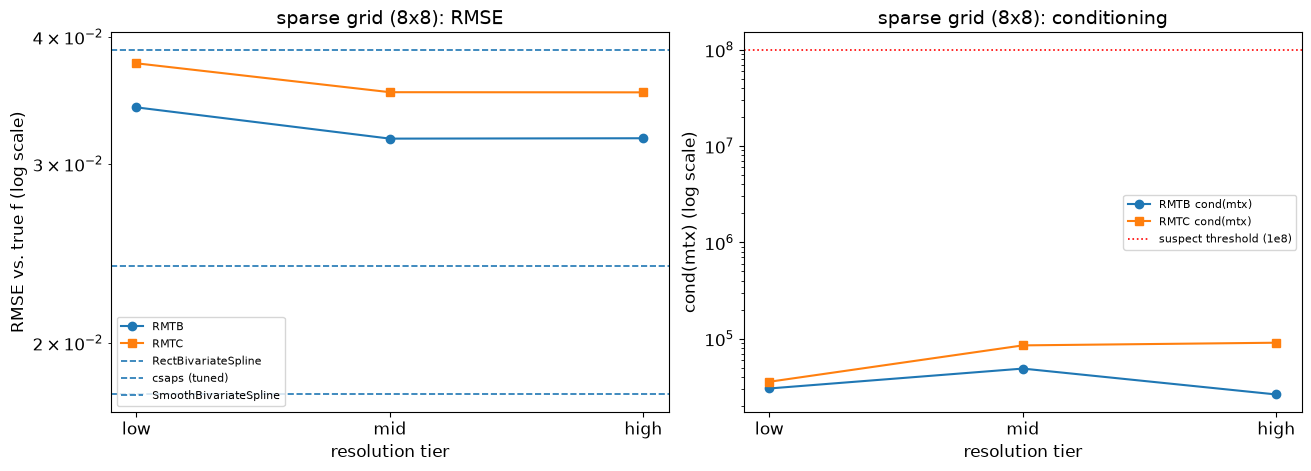

In [6]:
rng1 = np.random.default_rng(1)
g1 = np.linspace(0, 1, 8)
GX1, GY1 = np.meshgrid(g1, g1, indexing="ij")
X1 = np.column_stack([GX1.ravel(), GY1.ravel()])
y1 = true_f(X1) + 0.05 * rng1.standard_normal(len(X1))
Z1 = y1.reshape(8, 8)

rows1, alts1 = run_dataset_case("sparse grid (8x8)", X1, y1, n_side_eff=8,
                                 is_grid=True, g_side_1d=g1, Z_grid=Z1)


## Dataset 2 -- fine grid (40x40 = 1,600 points)

`seed=1`, uniform spacing. Native per-dimension count (40) already exceeds RMTC's
cap (25) by itself, so **all three** RMTC tiers collapse to 25 here -- RMTC gets no
resolution variation to study on this dataset at this compute budget, which is
itself a data point about its relative cost. RMTB fares better: "low"=40 stays
distinct, but "mid"(120) and "high"(400) both collapse to its cap of 60.

=== fine grid (40x40)  (n=1600, grid=True) ===


/tmp/ipykernel_519592/1993998085.py:5: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s)



Alternatives (best-tuned once, not resolution-tiered):
  RectBivariateSpline      RMSE=4.4887e-02  param=0.000e+00
  csaps (tuned)            RMSE=8.0987e-03  param=9.996e-01
  SmoothBivariateSpline    RMSE=1.1870e-02  param=7.598e+00

tier    RMTB res   RMTB RMSE       cond  RMTC res   RMTC RMSE       cond
low           40  8.5008e-03   2.61e+04                25  8.6571e-03   3.98e+04        
mid           60  8.4925e-03   2.65e+04                25  8.6571e-03   3.98e+04        
high          60  8.4925e-03   2.65e+04                25  8.6571e-03   3.98e+04        


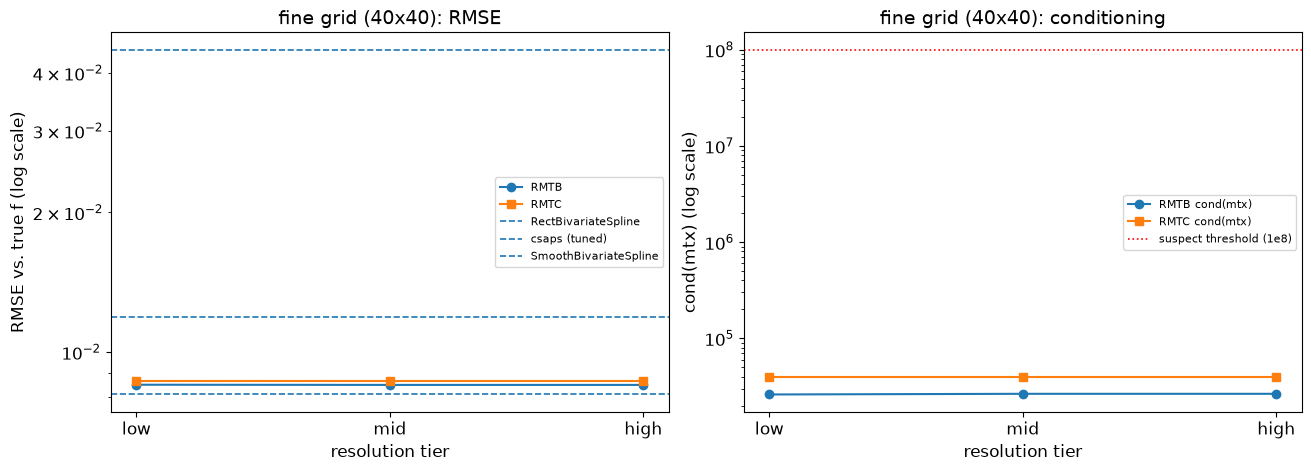

In [7]:
rng2 = np.random.default_rng(1)
g2 = np.linspace(0, 1, 40)
GX2, GY2 = np.meshgrid(g2, g2, indexing="ij")
X2 = np.column_stack([GX2.ravel(), GY2.ravel()])
y2 = true_f(X2) + 0.05 * rng2.standard_normal(len(X2))
Z2 = y2.reshape(40, 40)

rows2, alts2 = run_dataset_case("fine grid (40x40)", X2, y2, n_side_eff=40,
                                 is_grid=True, g_side_1d=g2, Z_grid=Z2)


## Dataset 3 -- sparse scattered (180 points)

`seed=2`, uniform-random in `[0,1]^2`. Only `SmoothBivariateSpline` is an applicable
alternative (`RectBivariateSpline`/`csaps` are grid-only). Effective per-dimension
resolution `sqrt(180)~=13.4`, rounded to 13 -- all three tiers stay distinct for
RMTB (13/39/60); RMTC's "mid" (39) already exceeds its cap of 25, so RMTC's
"mid"/"high" collapse together (13/25/25) while "low" stays distinct.

=== sparse scattered (n=180)  (n=180, grid=False) ===


/tmp/ipykernel_519592/1993998085.py:5: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s)



Alternatives (best-tuned once, not resolution-tiered):
  SmoothBivariateSpline    RMSE=2.0095e-02  param=1.669e+00

tier    RMTB res   RMTB RMSE       cond  RMTC res   RMTC RMSE       cond
low           13  2.5116e-02   2.81e+04                13  2.9993e-01   2.48e+09 SUSPECT
mid           39  2.5061e-02   2.72e+04                25  1.5166e+01   8.31e+13 SUSPECT
high          60  2.5057e-02   2.79e+04                25  1.5166e+01   8.31e+13 SUSPECT


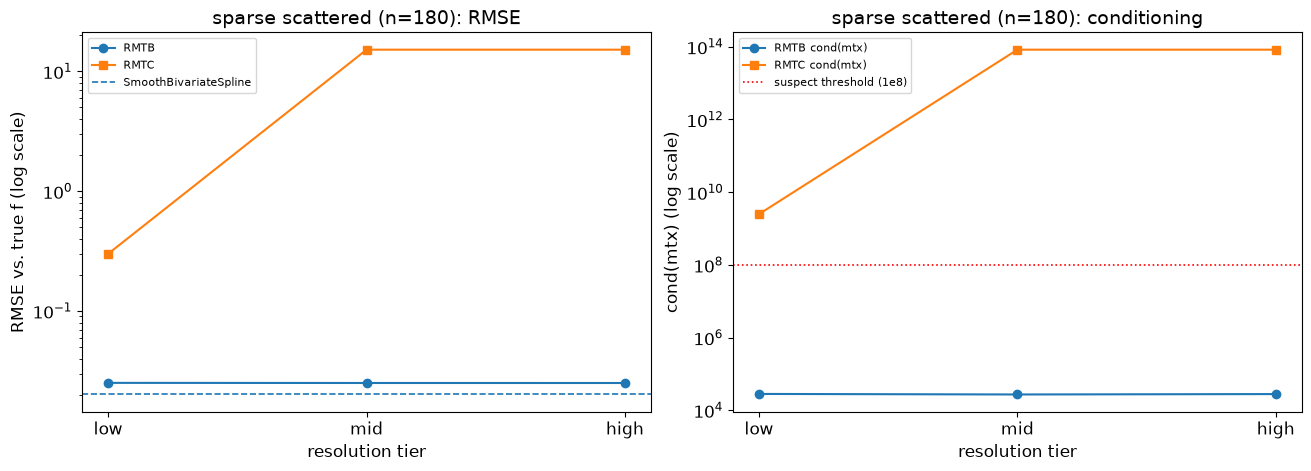

In [8]:
rng3 = np.random.default_rng(2)
X3 = rng3.uniform(0, 1, size=(180, 2))
y3 = true_f(X3) + 0.05 * rng3.standard_normal(180)

rows3, alts3 = run_dataset_case("sparse scattered (n=180)", X3, y3, n_side_eff=13,
                                 is_grid=False)


## Dataset 4 -- dense scattered (3,000 points)

`seed=2`, uniform-random. Only `SmoothBivariateSpline` applies (checked directly:
`SmoothBivariateSpline` fits this size in ~2ms, no scalability concern at this `n`).
Effective per-dimension resolution `sqrt(3000)~=54.8`, rounded to 55 -- already past
RMTC's cap (25), so all three RMTC tiers collapse to 25; RMTB keeps "low" distinct
(55 < 60) but "mid"/"high" (165/550) both collapse to its cap of 60.

=== dense scattered (n=3000)  (n=3000, grid=False) ===


/tmp/ipykernel_519592/1993998085.py:5: UserWarning: 
The required storage space exceeds the available storage space: nxest
or nyest too small, or s too small.
The weighted least-squares spline corresponds to the current set of
knots.
  sp = SmoothBivariateSpline(X[:, 0], X[:, 1], y, kx=3, ky=3, s=s)



Alternatives (best-tuned once, not resolution-tiered):
  SmoothBivariateSpline    RMSE=6.2258e-03  param=7.506e+00

tier    RMTB res   RMTB RMSE       cond  RMTC res   RMTC RMSE       cond
low           55  8.1136e-03   2.71e+04                25  2.9331e-02   1.98e+07        
mid           60  8.1124e-03   2.71e+04                25  2.9331e-02   1.98e+07        
high          60  8.1124e-03   2.71e+04                25  2.9331e-02   1.98e+07        


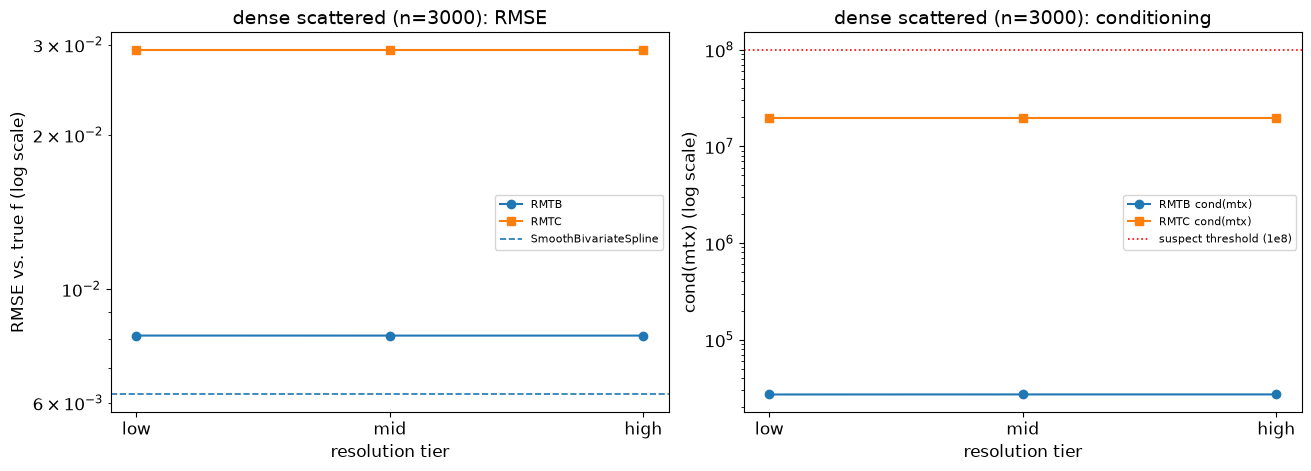

In [9]:
rng4 = np.random.default_rng(2)
X4 = rng4.uniform(0, 1, size=(3000, 2))
y4 = true_f(X4) + 0.05 * rng4.standard_normal(3000)

rows4, alts4 = run_dataset_case("dense scattered (n=3000)", X4, y4, n_side_eff=55,
                                 is_grid=False)


## Summary -- flagged failure / numerically-suspect cases

Per the stated criterion: RMTB/RMTC flagged if best-tuned RMSE exceeds every
applicable alternative's best-tuned RMSE by >2x, or `cond(mtx) > 1e8` regardless of
RMSE. This list is the deliverable Part II (variance) should consume -- both as
starting points to avoid (already-flagged configs) and as stress-test cases for
Phase D2/D4's calibration/scalability checks.

In [10]:
if not all_flags:
    print("No cases flagged -- RMTB/RMTC matched or beat every applicable "
          "alternative within 2x RMSE, and no cond(mtx) exceeded 1e8, across "
          "all 4 datasets x 3 resolution tiers tested.")
else:
    print(f"{'dataset':24s} {'tier':6s} {'model':5s} {'RMSE':>11s} {'best alt RMSE':>14s} "
          f"{'cond(mtx)':>11s}  reason")
    for f in all_flags:
        print(f"{f['dataset']:24s} {f['tier']:6s} {f['model']:5s} {f['rmse']:11.4e} "
              f"{f['best_alt_rmse']:14.4e} {f['cond']:11.2e}  {f['reason']}")


dataset                  tier   model        RMSE  best alt RMSE   cond(mtx)  reason
sparse grid (8x8)        low    RMTC   3.7672e-02     1.7791e-02    3.57e+04  RMSE>2x best alternative
sparse scattered (n=180) low    RMTC   2.9993e-01     2.0095e-02    2.48e+09  RMSE>2x best alternative & cond(mtx)>1e8
sparse scattered (n=180) mid    RMTC   1.5166e+01     2.0095e-02    8.31e+13  RMSE>2x best alternative & cond(mtx)>1e8
sparse scattered (n=180) high   RMTC   1.5166e+01     2.0095e-02    8.31e+13  RMSE>2x best alternative & cond(mtx)>1e8
dense scattered (n=3000) low    RMTC   2.9331e-02     6.2258e-03    1.98e+07  RMSE>2x best alternative
dense scattered (n=3000) mid    RMTC   2.9331e-02     6.2258e-03    1.98e+07  RMSE>2x best alternative
dense scattered (n=3000) high   RMTC   2.9331e-02     6.2258e-03    1.98e+07  RMSE>2x best alternative


## Key finding: RMTC fails specifically on scattered data; RMTB does not

**This is the headline result of Part I, not a footnote.** On both grid datasets,
RMTB and RMTC land in the same RMSE ballpark as each other and within a few x of the
alternatives (flagged only once, RMTC's "low" tier on the 8x8 grid, by a narrow
margin). On **both scattered datasets, RMTC fails badly while RMTB stays stable**:

- **Sparse scattered (n=180):** RMTB stays at `RMSE~0.025` across all three tiers
  (matching `SmoothBivariateSpline`'s `0.020` closely). RMTC's RMSE explodes:
  `0.30` at "low" (13 elements/dim), `15.2` at "mid"/"high" (25, capped) --
  two and four orders of magnitude worse, tracking `cond(mtx)` exploding in lockstep
  (`2.5e4` -> `2.5e9` -> `8.3e13`, crossing the suspect threshold at every tier).
- **Dense scattered (n=3000):** smaller but still clear gap -- RMTB `RMSE=0.0081`
  vs. RMTC `RMSE=0.0293` (~3.6x worse, ~4.7x worse than `SmoothBivariateSpline`'s
  `0.0062`), with RMTC's `cond(mtx)=2.0e7` about three orders of magnitude worse
  than RMTB's `2.7e4` at the same nominal resolution -- below the `1e8` suspect
  line here, but the same direction and likely the same mechanism as the sparse
  case at a less extreme data/resolution ratio.

**On the grid datasets this same mechanism is invisible** -- RMTB and RMTC perform
almost identically there, consistent with the sparse-180 and dense-3000 cases
flipping the data/element-count ratio rather than the resolution tiers themselves
being the cause (even RMTC's *lowest* resolution tier already fails on scattered
data, while its *highest* tier is fine on grid data at a larger absolute element
count).

**A plausible mechanism, offered as a hypothesis worth testing further, not an
established fact:** a regular grid guarantees every mesh element has nearby
training points; scattered data does not. RMTC's bicubic Hermite elements carry
derivative degrees of freedom at each node (confirmed in this notebook's own
compute-budget section: `dof = 4*(num_elements+1)^2`, not `(num_elements+1)^2`) --
elements with few or no nearby points leave *more* of these dof pinned only by the
thin `regularization_weight` floor than RMTB's plain value-only B-spline
coefficients would be, for the same nominal element count. The data-density
pattern across the two scattered cases is consistent with this: `n=180` over `13`
elements/dim is `~1` point per element on average (catastrophic, `cond` up to
`8.3e13`); `n=3000` over `25` elements/dim is `~4.8` points per element on average
(still ~1000x worse than RMTB, but three orders of magnitude short of "suspect").
This was not tested directly here (would need per-element point-count histograms)
and should be confirmed before being treated as settled.

**Consequence for Part II ("Gaussian RMTS"):** if variance is ever built on top of
RMTC the way Phase D plans for RMTB, **scattered/irregular training data is exactly
where to stress-test it first** -- this result suggests RMTC's mean fit is already
numerically compromised there, independent of anything variance-specific. RMTB
shows no comparable weakness in any case tested here.
